# PALLAS Campaign B — Direct Surrogate Modeling

This notebook investigates machine-learning models that predict
electron-beam properties from laser-plasma accelerator settings.

We begin with a linear regression baseline and then investigate
nonlinear models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

## 1. Load Campaign B Dataset

Load the PIC simulation results for Campaign B and inspect
the available input and output variables.

In [11]:
DATA_PATH = Path("data/pallas_hackathon_data")

B = pd.read_parquet(DATA_PATH / "campaign_B.parquet")

print("Campaign B shape:", B.shape)

#display(B.head())

Campaign B shape: (5286, 35)


In [7]:
for i, col in enumerate(B.columns, start=1):
    print(f"{i:2d}. {col}")

 1. config
 2. a_0
 3. x_of
 4. P_max
 5. cN2_max
 6. L_inj
 7. dip_frac
 8. dE_std
 9. dE_mad
10. z_avg
11. sigma_x
12. sigma_y
13. sigma_z
14. i_peak
15. q_end
16. n_emit_x
17. n_emit_y
18. n_emitTS_x
19. n_emitTS_y
20. alpha_x
21. beta_x
22. gamma_x
23. alpha_y
24. beta_y
25. gamma_y
26. div_rms
27. E_med_MeV
28. E_mean_MeV
29. q_pC
30. injected
31. ener_axis_MeV
32. spec
33. spec_common
34. x_p
35. n_e_p


## 2. Data Preparation

Campaign B contains simulations with and without electron injection.

We first investigate the injection status and missing values
before selecting the training dataset.

In [8]:
# Check injection status
print("Injection status:")
print(B["injected"].value_counts(dropna=False))

# Check missing values in the beam properties
TARGETS = ["E_med_MeV", "dE_mad", "q_end"]

print("\nMissing values:")
print(B[TARGETS].isna().sum())

# Examine output statistics
display(B[TARGETS].describe())

Injection status:
injected
True     2882
False    2404
Name: count, dtype: int64

Missing values:
E_med_MeV    2404
dE_mad       2404
q_end        2404
dtype: int64


,E_med_MeV,dE_mad,q_end
count,2882.000000,2882.000000,2.882000e+03
mean,136.419637,0.094704,8.208297e-11
std,32.917334,0.075778,6.854726e-11
min,66.973032,0.019029,3.037840e-12
25%,111.848557,0.051676,1.867743e-11
50%,133.960170,0.075120,6.846694e-11
75%,159.129929,0.102185,1.309547e-10
max,241.277909,0.508474,3.006102e-10


## 3. Feature Selection and Train-Test Split

We select five accelerator parameters as inputs and three
electron-beam properties as outputs.

Only simulations with successful electron injection are used
for this initial regression model.

The dataset is divided into:
- 80% training data
- 20% testing data

In [9]:
# Input parameters
FEATURES = [
    "P_max",
    "cN2_max",
    "L_inj",
    "dip_frac",
    "x_of"
]

# Output parameters
TARGETS = [
    "E_med_MeV",
    "dE_mad",
    "q_end"
]

# Select successfully injected simulations
B_injected = B[B["injected"] == True].copy()

# Remove rows with missing values in the selected columns
B_injected = B_injected.dropna(subset=FEATURES + TARGETS)

# Separate inputs and outputs
X = B_injected[FEATURES]
y = B_injected[TARGETS]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training simulations:", len(X_train))
print("Testing simulations:", len(X_test))

display(X_train.head())
display(y_train.head())

Training simulations: 2305
Testing simulations: 577


,P_max,cN2_max,L_inj,dip_frac,x_of
3345,5297.691325,0.109232,0.646659,0.432330,998.262860
2657,4889.030733,0.187174,0.553145,0.151877,1117.476091
1839,5062.863507,0.132452,0.716273,0.276130,1118.149005
5021,5835.020159,0.221647,0.479491,0.197419,969.323970
1263,6992.711220,0.198525,0.723342,0.370866,662.193140


,E_med_MeV,dE_mad,q_end
3345,177.209662,0.072689,7.550709e-12
2657,142.610206,0.089909,3.127675e-12
1839,149.427769,0.076019,2.005660e-11
5021,144.610473,0.139485,2.202407e-11
1263,99.125958,0.356138,1.811335e-10


## 4. Baseline Model — Linear Regression

We train a linear regression model to predict three electron-beam
properties from five accelerator parameters.

The model predicts:
- Median beam energy (E_med_MeV)
- Energy spread (dE_mad)
- Beam charge (q_end)

We evaluate its performance using the R² score.

In [12]:
# Create the Linear Regression model
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Train using the training dataset
linear_model.fit(X_train, y_train)

# Predict beam properties for unseen simulations
y_pred = linear_model.predict(X_test)

# Calculate R² for each output
linear_scores = {}

for i, target in enumerate(TARGETS):
    linear_scores[target] = r2_score(
        y_test[target],
        y_pred[:, i]
    )

# Calculate the overall mean R²
linear_scores["mean"] = np.mean(
    [linear_scores[target] for target in TARGETS]
)

# Display results
display(
    pd.DataFrame.from_dict(
        linear_scores,
        orient="index",
        columns=["R²"]
    ).round(4)
)

,R²
E_med_MeV,0.9381
dE_mad,0.3128
q_end,0.9172
mean,0.7227


## 5. Random Forest Regression

In [13]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)

# Calculate R²
rf_scores = {}

for i, target in enumerate(TARGETS):
    rf_scores[target] = r2_score(
        y_test[target],
        rf_pred[:, i]
    )

rf_scores["mean"] = np.mean(
    [rf_scores[target] for target in TARGETS]
)

# Compare with Linear Regression
comparison = pd.DataFrame({
    "Linear Regression": linear_scores,
    "Random Forest": rf_scores
})

display(comparison.round(4))

,Linear Regression,Random Forest
E_med_MeV,0.9381,0.9660
dE_mad,0.3128,0.6611
q_end,0.9172,0.8886
mean,0.7227,0.8386


## 6. Random Forest with Target Standardization

In [14]:
from sklearn.compose import TransformedTargetRegressor

# Random Forest with standardized outputs
rf_scaled = TransformedTargetRegressor(
    regressor=RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),
    transformer=StandardScaler()
)

# Train
rf_scaled.fit(X_train, y_train)

# Predict in original physical units
rf_scaled_pred = rf_scaled.predict(X_test)

# Evaluate
rf_scaled_scores = {
    target: r2_score(y_test[target], rf_scaled_pred[:, i])
    for i, target in enumerate(TARGETS)
}

rf_scaled_scores["mean"] = np.mean(
    [rf_scaled_scores[target] for target in TARGETS]
)

# Compare all three models
comparison = pd.DataFrame({
    "Linear Regression": linear_scores,
    "Random Forest": rf_scores,
    "RF + Target Scaling": rf_scaled_scores
})

display(comparison.round(4))

,Linear Regression,Random Forest,RF + Target Scaling
E_med_MeV,0.9381,0.9660,0.9582
dE_mad,0.3128,0.6611,0.8221
q_end,0.9172,0.8886,0.9459
mean,0.7227,0.8386,0.9087


## 7. Neural Network — MLP Regression

In [15]:
from sklearn.neural_network import MLPRegressor

# Define MLP model
mlp_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(128, 64, 32),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            alpha=0.001,
            max_iter=1500,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=30,
            random_state=42
        )
    ),
    transformer=StandardScaler()
)

# Train
mlp_model.fit(X_train, y_train)

# Predict
mlp_pred = mlp_model.predict(X_test)

# Evaluate
mlp_scores = {
    target: r2_score(y_test[target], mlp_pred[:, i])
    for i, target in enumerate(TARGETS)
}

mlp_scores["mean"] = np.mean(
    [mlp_scores[target] for target in TARGETS]
)

# Compare models
comparison = pd.DataFrame({
    "Linear Regression": linear_scores,
    "Random Forest": rf_scores,
    "RF + Target Scaling": rf_scaled_scores,
    "MLP": mlp_scores
})

display(comparison.round(4))

,Linear Regression,Random Forest,RF + Target Scaling,MLP
E_med_MeV,0.9381,0.9660,0.9582,0.9966
dE_mad,0.3128,0.6611,0.8221,0.9763
q_end,0.9172,0.8886,0.9459,0.9960
mean,0.7227,0.8386,0.9087,0.9896


## 8. MLP Cross-Validation

In [16]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import make_scorer
from sklearn.base import clone

# Define 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define R² scoring for each output
def target_r2(index):
    def score(y_true, y_pred):
        return r2_score(
            np.asarray(y_true)[:, index],
            np.asarray(y_pred)[:, index]
        )
    return make_scorer(score)

scoring = {
    "E_med_MeV": target_r2(0),
    "dE_mad": target_r2(1),
    "q_end": target_r2(2),
    "mean": "r2"
}

# Perform cross-validation on training data only
cv_results = cross_validate(
    clone(mlp_model),
    X_train,
    y_train,
    cv=kf,
    scoring=scoring,
    n_jobs=1
)

# Display results for each fold
cv_df = pd.DataFrame({
    "E_med_MeV": cv_results["test_E_med_MeV"],
    "dE_mad": cv_results["test_dE_mad"],
    "q_end": cv_results["test_q_end"],
    "Mean R²": cv_results["test_mean"]
})

cv_df.index = [f"Fold {i}" for i in range(1, 6)]

display(cv_df.round(4))

,E_med_MeV,dE_mad,q_end,Mean R²
Fold 1,0.9965,0.9818,0.9960,0.9914
Fold 2,0.9968,0.9707,0.9949,0.9875
Fold 3,0.9960,0.9739,0.9970,0.9890
Fold 4,0.9963,0.9773,0.9969,0.9902
Fold 5,0.9967,0.9775,0.9959,0.9900


Maximum allowed epochs: 1500
Actual training epochs: 198
Best validation epoch: 167
Best internal validation R²: 0.9918333624108268


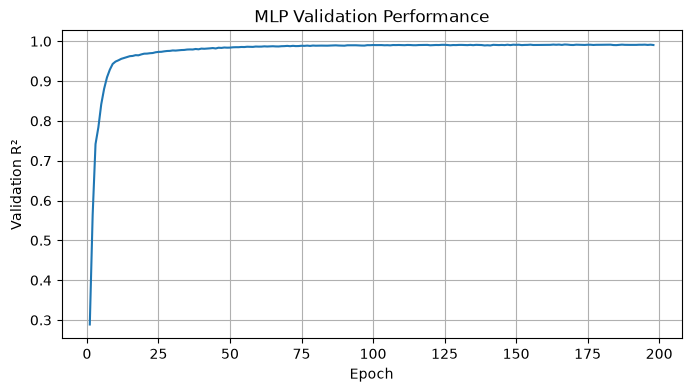

In [17]:
# Extract the trained MLP
nn = mlp_model.regressor_.named_steps["mlpregressor"]

print("Maximum allowed epochs:", nn.max_iter)
print("Actual training epochs:", nn.n_iter_)
print("Best validation epoch:", np.argmax(nn.validation_scores_) + 1)
print("Best internal validation R²:", nn.best_validation_score_)

# Plot validation performance
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(nn.validation_scores_) + 1),
         nn.validation_scores_)

plt.xlabel("Epoch")
plt.ylabel("Validation R²")
plt.title("MLP Validation Performance")
plt.grid(True)
plt.show()

## 10. MLP Hyperparameter Optimization — GridSearchCV

In [18]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter combinations
param_grid = {
    "regressor__mlpregressor__hidden_layer_sizes": [
        (64, 32),
        (128, 64, 32),
        (256, 128, 64)
    ],
    "regressor__mlpregressor__learning_rate_init": [
        0.0005, 0.001
    ],
    "regressor__mlpregressor__alpha": [
        0.0001, 0.001
    ],
    "regressor__mlpregressor__max_iter": [
        300, 600
    ]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=mlp_model,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=2,
    refit=True
)

# Run optimization on training data only
grid_search.fit(X_train, y_train)

print("Best cross-validation R²:", grid_search.best_score_)
print("\nBest hyperparameters:")

for parameter, value in grid_search.best_params_.items():
    print(parameter, ":", value)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/home/sara/miniconda3/envs/ai-hackathon/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/sara/miniconda3/envs/ai-hackathon/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/sara/miniconda3/envs/ai-hackathon/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/sara/miniconda3/envs/ai-hackathon/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't 

Best cross-validation R²: 0.9914837260468825

Best hyperparameters:
regressor__mlpregressor__alpha : 0.001
regressor__mlpregressor__hidden_layer_sizes : (256, 128, 64)
regressor__mlpregressor__learning_rate_init : 0.0005
regressor__mlpregressor__max_iter : 300
[CV] END regressor__mlpregressor__alpha=0.0001, regressor__mlpregressor__hidden_layer_sizes=(64, 32), regressor__mlpregressor__learning_rate_init=0.0005, regressor__mlpregressor__max_iter=300; total time=   3.9s
[CV] END regressor__mlpregressor__alpha=0.0001, regressor__mlpregressor__hidden_layer_sizes=(64, 32), regressor__mlpregressor__learning_rate_init=0.001, regressor__mlpregressor__max_iter=300; total time=   3.7s
[CV] END regressor__mlpregressor__alpha=0.0001, regressor__mlpregressor__hidden_layer_sizes=(64, 32), regressor__mlpregressor__learning_rate_init=0.001, regressor__mlpregressor__max_iter=300; total time=   3.9s
[CV] END regressor__mlpregressor__alpha=0.0001, regressor__mlpregressor__hidden_layer_sizes=(128, 64, 32)

In [21]:
# Best model from GridSearchCV
best_model = grid_search.best_estimator_

# Predict on the independent test dataset
y_pred_best = best_model.predict(X_test)

# Calculate R² for each beam property
best_scores = {}

for i, target in enumerate(TARGETS):
    best_scores[target] = r2_score(
        y_test[target],
        y_pred_best[:, i]
    )

best_scores["mean"] = np.mean(
    [best_scores[target] for target in TARGETS]
)

# Compare with previous models
final_comparison = pd.DataFrame({
    "Linear Regression": linear_scores,
    "Random Forest": rf_scores,
    "RF + Target Scaling": rf_scaled_scores,
    "Optimized MLP": best_scores
})

display(final_comparison.round(4))

,Linear Regression,Random Forest,RF + Target Scaling,Optimized MLP
E_med_MeV,0.9381,0.9660,0.9582,0.9973
dE_mad,0.3128,0.6611,0.8221,0.9795
q_end,0.9172,0.8886,0.9459,0.9970
mean,0.7227,0.8386,0.9087,0.9912
